(gene-sets)=
# Gene sets and pathways

Test which pathways respond to a treatment with {api}`camera`, which asks of every set
of a collection whether its genes change more than the other genes, and allows for the
correlation between them [@wu2012]; {api}`gsea` asks it along a ranking of every gene,
as fgsea does [@korotkevich2021]. This page applies both to the CD14+ monocytes of the
Kang data [@kang2018], with the targets of each transcription factor of CollecTRI as
the sets, then tests one set chosen in advance, the Hallmark interferon-alpha response
of MSigDB [@liberzon2015], and the genes called significant (the `kang2018` and
`hallmark_interferon_alpha` datasets of the [Datasets](../reference/datasets.md)
page). [Gene-set tests](../statistics/gene_set_tests.md) and [Over-representation and
GSEA](../statistics/over_representation_and_gsea.md) explain the tests.

camera, fry and roast work on the linear model of one cell type, so they take a
result of {api}`limma_voom` and read that cell type's values, weights, design and
contrast from it ({api}`DifferentialExpressionResult.fit`).

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np

import cytepool
from cytepool import (
    Design,
    camera,
    collectri,
    fry,
    gsea,
    limma_voom,
    over_representation,
    read_cube,
    roast,
)
from cytepool.plotting import (
    plot_barcode,
    plot_enrichment,
    plot_gene_sets,
    plot_gsea_table,
    plot_over_representation,
)

kang = read_cube("kang2018.cube.zarr")
monocytes = "CD14+ Monocytes"
design = Design(
    kang.samples,
    "~ donor + condition",
    levels={"condition": ["ctrl", "stim"]},
    contrasts={"stim_vs_ctrl": "conditionstim"},
)
result = limma_voom(kang, design, groups=monocytes)
tested = result.table()["symbol"]  # the one cell type and contrast

print(f"CytePool {cytepool.__version__}")
print(f"{len(tested):,} genes tested in the {monocytes}")

CytePool 0.1.dev70+g194507939
5,125 genes tested in the CD14+ Monocytes


## A collection of sets

Any collection of sets works, such as a GMT file of MSigDB, Reactome or the Gene
Ontology read by {api}`read_gmt`, under its provider's terms; CytePool bundles none
([Gene-set collections](../statistics/gene_set_tests.md#gene-set-collections)). Here
each transcription factor's targets in CollecTRI [@muellerdott2023] form a set.
{api}`collectri` downloads it on first use and returns, by default, the interactions
whose sources allow commercial use ([Datasets](../reference/datasets.md#networks)
gives the terms). {api}`Network.to_gene_sets` makes each regulator's targets a set,
without the signs of their regulation; {api}`GeneSets.restrict_to` keeps each set's
tested genes and {api}`GeneSets.filter_by_size` the sets of 15 to 500 of them. camera
then ranks them.

GeneSets: 199 sets of 15 to 435 genes, 1,893 genes in all
  name: CollecTRI; version: 2.0 (Zenodo record 8192729); licence: CC BY 4.0
        (Zenodo record 8192729); level 'commercial': the interactions of
        resources that OmniPath lists for commercial use, without those that
        GEREDB (listed for academic use) alone supports; each resource keeps its
        own terms
  read from CollecTRI_regulons.csv, SHA-256
      4473c9189dd53dacc80297709ad1452dda1086a1cc2185f9a56146c261668701
  sets: MYC (383), SPI1 (133), SMAD3 (41) and 196 more


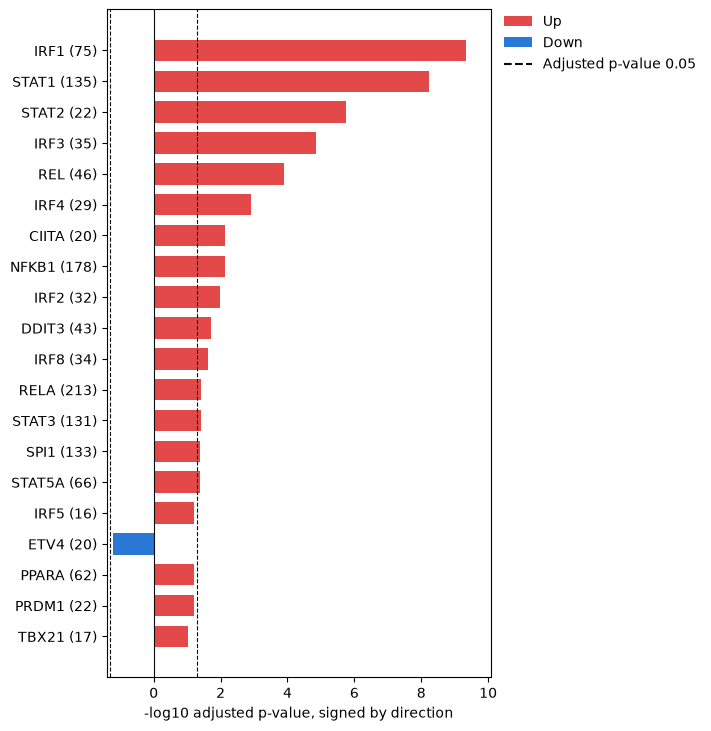

In [2]:
regulons = collectri().to_gene_sets().restrict_to(tested).filter_by_size(15, 500)
print(regulons)
ranked = camera(result, regulons, id_column="symbol")
plot_gene_sets(ranked)
plt.show()

The targets of interferon regulatory factors and of STAT1 and STAT2 rise more than
the other genes.

## Gene set enrichment analysis

{api}`gsea` ranks every tested gene by its moderated t-statistic and asks whether a
set's genes gather at the top or the bottom of the ranking, as fgsea does
[@subramanian2005; @korotkevich2021]. It needs only a statistic for every gene, from any
method. The enrichment plot follows the running score of one set down the ranking, and
fgsea's table shows the top sets with their genes.

/tmp/ipykernel_1168275/1970039944.py:1: RuntimeWarning: 1 gene set(s) have fewer than 10 random scores of the sign of their enrichment
score among 1000 permutations, but some; their normalized scores and p-values
are NaN. More permutations (n_permutations=10000) may give them enough
  enrichment = gsea(result, regulons, id_column="symbol", rng=1)


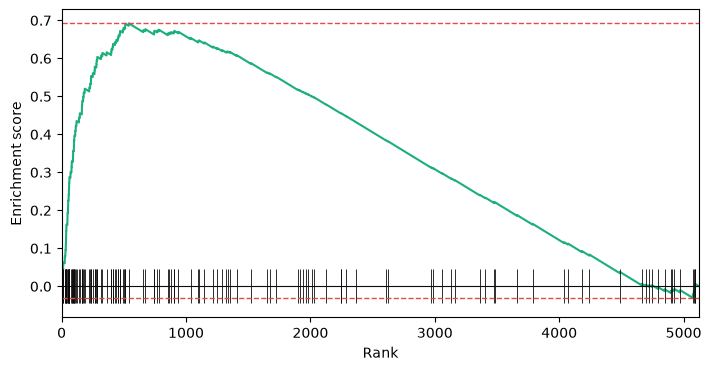

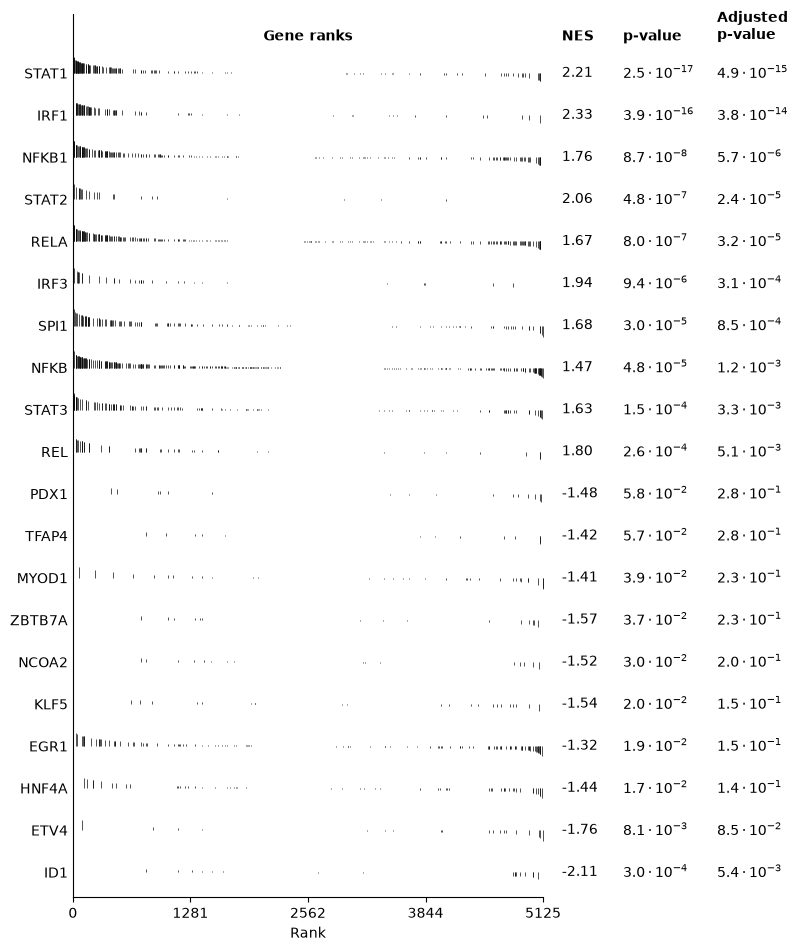

In [3]:
enrichment = gsea(result, regulons, id_column="symbol", rng=1)
plot_enrichment(result, regulons["STAT1"], id_column="symbol")
plt.show()
plot_gsea_table(result, regulons, enrichment, id_column="symbol")
plt.show()

GSEA ranks first the targets of the regulators that camera ranked first, STAT1, IRF1
and STAT2 among them, and finds ID1's targets at the bottom. It warns that one set, the
383 targets of MYC, has too few random scores of its sign to be tested; its p-value is
missing, as fgsea leaves it ([p-values from random
sets](../statistics/over_representation_and_gsea.md#gsea-p-values)).

## Choices

- **One set or many.** To rank a collection, use a competitive test: {api}`camera` by
  default, or {api}`romer`, which takes a result of {api}`limma_trend`, as it has no
  observation weights. For a set chosen in advance, a self-contained test, {api}`fry`
  or {api}`roast`, answers whether it responds at all, as below; {api}`mroast` runs
  roast on many sets with the same rotations ([Competitive or
  self-contained](../statistics/gene_set_tests.md#competitive-and-self-contained)).
- **camera's correlation.** The default inter-gene correlation, 0.01, ranks sets of
  co-regulated genes higher; `inter_gene_correlation=None` estimates it for each set,
  which controls the error rate of each set more strictly
  ([camera](../statistics/gene_set_tests.md#camera)).
- **camera, over-representation or GSEA.** camera uses every gene's statistic and
  allows for the correlation between the genes of a set; over-representation needs
  only a list of genes, and depends on the cutoff that made it, as below; GSEA needs
  only a ranking, from any method. Over-representation and GSEA take genes as
  independent, which makes their p-values too small for sets of genes that respond
  together ([Genes that respond
  together](../statistics/gene_set_tests.md#correlated-genes)).
- **Rotations and permutations.** roast's smallest p-value is $1/(B + 1)$ for the
  two-sided and mixed alternatives and $1/(2B + 1)$ for up or down, with $B$ rotations
  (`n_rotations`, 1,999 by default): 0.0005 and 0.00025. romer's smallest is
  $1/(B + 1)$ ([roast and mroast](../statistics/gene_set_tests.md#roast)). The
  rotations and GSEA's random sets are drawn from `rng`: pass a seed to get the same
  p-values every time.
- **The collection.** Restrict the sets to the genes tested and to a range of sizes
  before testing, and name genes as the data do, with `id_column`: symbols here, or
  the Ensembl ids of `feature_id`, the default.
- **Scores per sample.** To compare samples rather than test one contrast, score each
  set or regulator in every sample: [Pathway and regulator
  activity](pathway_activity.ipynb).

### One set chosen in advance

limma's barcode plot shows where the set's genes fall among all genes ranked by their
moderated t-statistic, with a worm above that rises where the set is enriched. fry and
roast test whether the set responds at all, and camera, for comparison, whether it
responds more than the other genes.

92 of the set's 97 genes are among the 5,125 genes tested


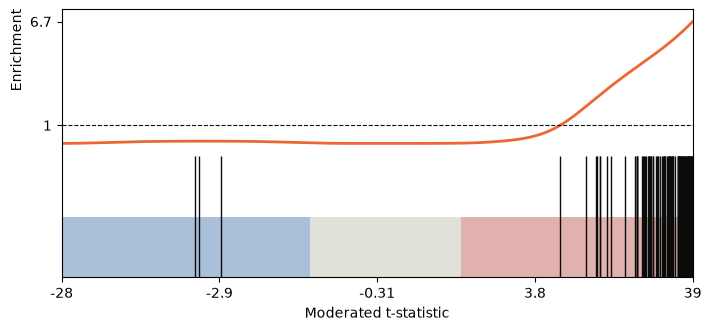

fry, self-contained     p-value 5.8e-08
roast, self-contained   p-value 0.00025
camera, competitive     p-value 2.5e-35


In [4]:
with open("hallmark_interferon_alpha_response.json") as file:
    hallmark = json.load(file)
# Two genes of the set have earlier symbols in the annotation of these data.
interferon = [hallmark["earlier_symbols"].get(gene, gene) for gene in hallmark["genes"]]
print(
    f"{np.isin(interferon, tested).sum()} of the set's {len(interferon)} genes are "
    f"among the {len(tested):,} genes tested"
)

table = result.table(monocytes, "stim_vs_ctrl")
plot_barcode(table, np.isin(table["symbol"], interferon))
plt.show()

sets = {"interferon-alpha response": interferon}
rotations = roast(result, interferon, id_column="symbol", rng=1)
tests = {
    "fry, self-contained": fry(result, sets, id_column="symbol")["p_value"],
    "roast, self-contained": rotations["up_p_value"],
    "camera, competitive": camera(result, sets, id_column="symbol")["p_value"],
}
for name, p_value in tests.items():
    print(f"{name:<23} p-value {p_value[0]:.2g}")

Nearly all the set's genes go up with the stimulation. The three tests agree, but
answer different questions. fry and roast ask whether the set's genes respond at all:
fry's p-value comes from a t distribution on the design's seven residual degrees of
freedom, and roast's, 0.00025, is the smallest its 1,999 rotations give for one
direction. camera asks whether they respond more than the other genes, a stricter
question when thousands of genes respond, and compares them with every other gene.

### Over-representation among the changed genes

{api}`over_representation` asks whether the genes called significant hold more of a
set's genes than chance would give, for the genes up and those down, as limma's
`kegga` tests a fit of limma, and for both together [@young2010]. Its universe is the
genes tested ([The
universe](../statistics/over_representation_and_gsea.md#over-representation-universe)).

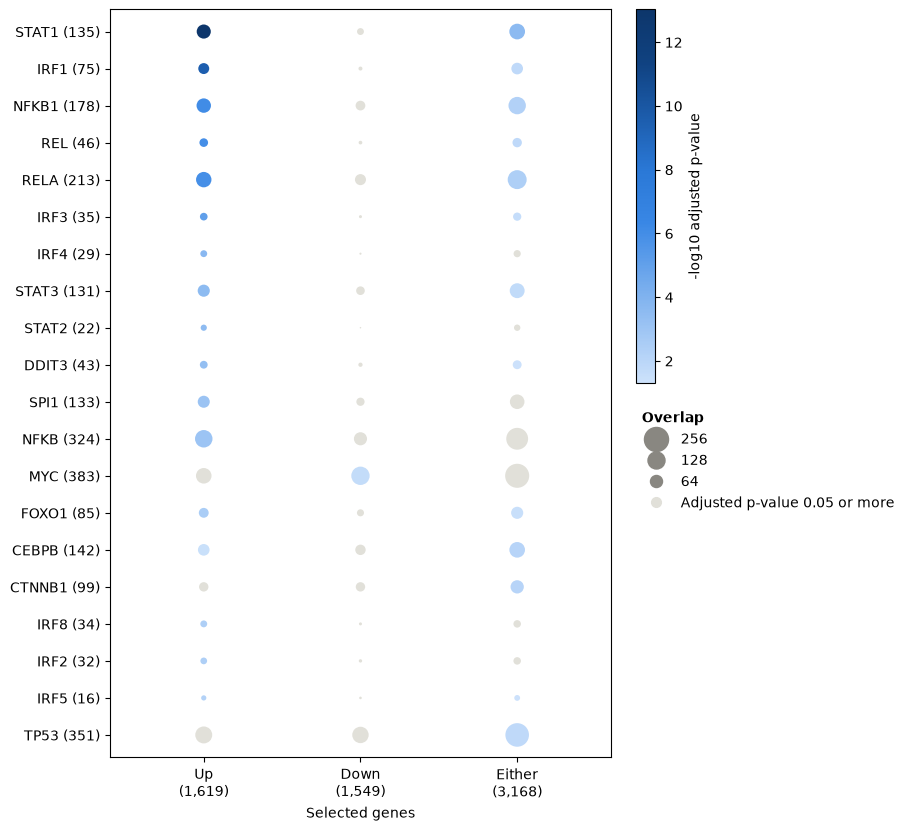

In [5]:
enriched = over_representation(result, regulons, id_column="symbol")
plot_over_representation(enriched)
plt.show()

The genes up hold the targets of the regulators that camera and GSEA ranked first, and
the genes down hold MYC's. The lists, and so the result, depend on the cutoff of 0.05
that made them.